# Statistics & Probability for Machine Learning




In [1]:
# Setup
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
np.random.seed(42)
print("Libraries loaded ✅")


Libraries loaded ✅


## 1. What is the Central Limit Theorem (CLT)?

**CLT:** If you repeatedly take random samples from *any* population (regardless of its shape) and calculate the **mean of each sample**, the distribution of those sample means will approach a **Normal Distribution** as the sample size grows — even if the original population is not normal.

**Real-life example:** Imagine the *time it takes customers to check out* at a grocery store — this could be skewed (some people take very long). But if you record the *average* checkout time for random groups of 30 customers, over and over, those averages will form a bell-shaped curve, no matter how skewed the individual times were.

## 2. Use of CLT in Machine Learning

- **Justifies using normal-distribution-based methods** (confidence intervals, hypothesis tests, t-tests) on sample statistics like averages — even when raw data isn't normal.
- **Model evaluation:** when you evaluate a model using k-fold cross-validation, the *average* accuracy across folds tends to behave normally, letting you compute confidence intervals for model performance.
- **A/B testing** in ML-driven products (e.g., comparing conversion rates of two recommendation algorithms) relies on CLT to justify using z-tests/t-tests on the *sample mean* difference.
- **Bootstrapping / ensemble methods** (e.g., bagging, random forests) rely on the idea that aggregating many samples smooths out noise, similar in spirit to CLT.


CLT tells us that averages of many samples behave approximately normally.

Because of that, ML practitioners can perform above analysis. Because,  all of those methods either:

Assume a normal distribution, or
Use the CLT to approximate a normal distribution for sample statistics, even when the raw data is not normal.

## 3. Empirical Rule (Empirical Formula) of the Normal Distribution

Also called the **68-95-99.7 rule**. For any normal distribution:

- **68%** of data lies within **1 standard deviation** of the mean: `[μ − σ, μ + σ]`
- **95%** of data lies within **2 standard deviations**: `[μ − 2σ, μ + 2σ]`
- **99.7%** of data lies within **3 standard deviations**: `[μ − 3σ, μ + 3σ]`

**Real-life example:** Adult male heights have mean ≈ 175 cm, std dev ≈ 7 cm. So about 68% of men are between 168–182 cm, 95% between 161–189 cm, and almost all (99.7%) between 154–196 cm.


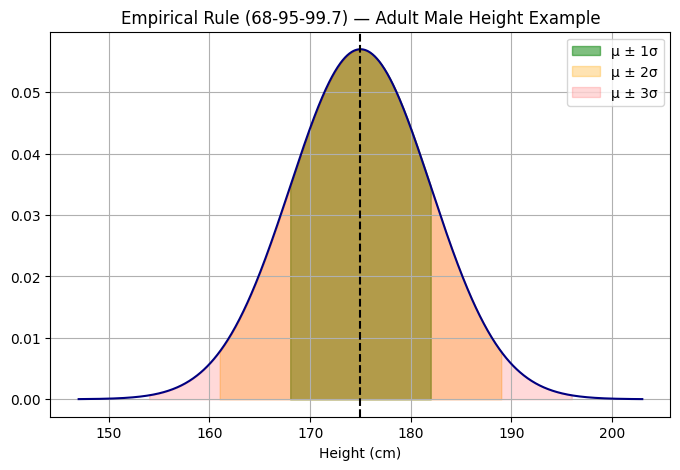

Within 1 std dev: 68.3%
Within 2 std dev: 95.4%
Within 3 std dev: 99.7%


In [3]:
mu, sigma = 175, 7
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
y = stats.norm.pdf(x, mu, sigma)

plt.plot(x, y, color='navy')
for k, alpha, color in zip([1, 2, 3], [0.5, 0.3, 0.15], ['green', 'orange', 'red']):
    plt.fill_between(x, y, where=(x >= mu - k*sigma) & (x <= mu + k*sigma), color=color, alpha=alpha,
                      label=f'μ ± {k}σ')
plt.axvline(mu, color='black', linestyle='--')
plt.title("Empirical Rule (68-95-99.7) — Adult Male Height Example")
plt.xlabel("Height (cm)")
plt.legend()
plt.show()

for k in [1, 2, 3]:
    pct = stats.norm.cdf(mu + k*sigma, mu, sigma) - stats.norm.cdf(mu - k*sigma, mu, sigma)
    print(f"Within {k} std dev: {pct*100:.1f}%")


## 4. What is the Standard Normal Distribution?

The **Standard Normal Distribution** is a special case of the normal distribution with:
- **Mean (μ) = 0**
- **Standard deviation (σ) = 1**

Any normal distribution can be converted into the standard normal using the **Z-score**:

$$ Z = \frac{x - \mu}{\sigma} $$

**Real-life example:** If exam scores have mean 70 and std dev 10, a score of 85 converts to `Z = (85-70)/10 = 1.5` — meaning that score is 1.5 standard deviations above average. This lets you compare scores from *different* exams (different μ, σ) on the same standard scale.


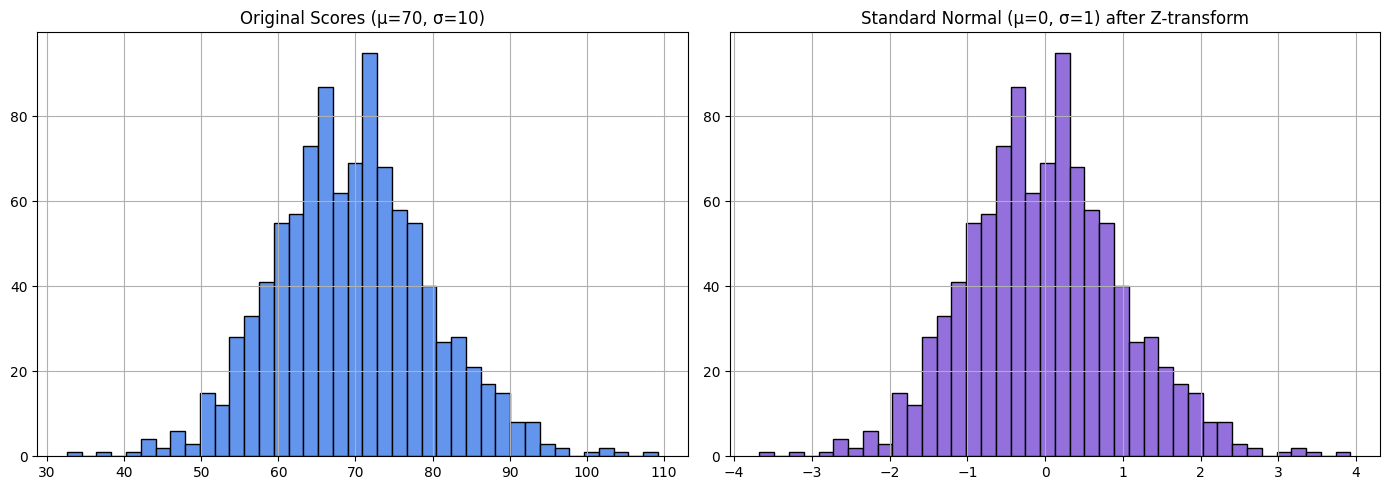

In [4]:
exam_scores = np.random.normal(70, 10, 1000)
z_scores = (exam_scores - np.mean(exam_scores)) / np.std(exam_scores)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(exam_scores, bins=40, color='cornflowerblue', edgecolor='black')
axes[0].set_title("Original Scores (μ=70, σ=10)")
axes[1].hist(z_scores, bins=40, color='mediumpurple', edgecolor='black')
axes[1].set_title("Standard Normal (μ=0, σ=1) after Z-transform")
plt.tight_layout()
plt.show()


## 5. Normal Distribution WITHOUT standardizing — is Mean = Median = Mode?

**Yes.** Standardizing (converting to Z-scores) only **rescales** the data — it does *not* change the *shape* of the distribution.

Any normal distribution — standardized or not, whatever its μ and σ — is **perfectly symmetric**, so:

$$ \text{Mean} = \text{Median} = \text{Mode} $$

This holds true **regardless of the values of μ and σ**. Standardization just shifts the center to 0 and rescales the spread to 1; it doesn't skew or distort the curve.


## 7. What is a Measure of Dispersion?

A **measure of dispersion** tells you **how spread out** the data is — how much individual values differ from the center (mean). Two datasets can have the *same mean* but very *different spread*.

**Real-life example:** Two classes both average 70% on a test. In Class A everyone scored 65-75% (low dispersion, consistent). In Class B scores ranged from 20% to 100% (high dispersion, inconsistent) — the mean alone hides this difference!

Common measures: **Range, Variance, Standard Deviation, IQR** (covered earlier for box plots).


## 8. Range, Variance, and Standard Deviation of a Normal Distribution

- **Range** = Max − Min. For a *theoretical* normal distribution the range is infinite (the tails never truly hit zero), but for real/sample data it's simply the difference between the largest and smallest observed values.
- **Variance (σ²)** = the average of the squared deviations from the mean:
$$ \sigma^2 = \frac{1}{n}\sum (x_i - \mu)^2 $$
- **Standard Deviation (σ)** = square root of variance — brings the units back to the original scale (variance is in *squared* units, which is hard to interpret).

**Real-life example:** If daily temperatures have σ² = 16 (°C²), then σ = 4°C — meaning typical days vary by about ±4°C from the average, a number that's actually interpretable (unlike 16 °C²).


## 9. What happens if variance is 0 (or not there)? What do different Std Devs mean?

- **Variance = 0** → every single data point is **identical** (no spread at all). E.g., if every product on an assembly line is exactly 10.000 cm — no variation, no useful "distribution" to analyze, and features like this carry **zero predictive information** for ML models (a constant column tells the model nothing).
- **Small std dev** → data tightly clustered around the mean → consistent/predictable process (e.g., a well-calibrated machine).
- **Large std dev** → data widely spread → inconsistent/unpredictable process (e.g., a poorly-calibrated machine, or highly volatile stock prices).

**Real-life example:** Two factories both produce bolts averaging 10mm diameter. Factory A has σ = 0.01mm (very consistent, high quality). Factory B has σ = 0.5mm (inconsistent, many bolts out of spec) — same mean, very different reliability.


## 11. Normalization vs Standardization vs Z-score Scaling

| | **Normalization (Min-Max Scaling)** | **Standardization (Z-score Scaling)** |
|---|---|---|
| Formula | $x' = \frac{x - min}{max - min}$ | $x' = \frac{x - \mu}{\sigma}$ |
| Resulting range | Fixed range, usually [0, 1] | Mean = 0, Std Dev = 1 (range varies) |
| Sensitive to outliers? | Yes, very (min/max shift easily) | Less sensitive |
| Best when | Data has a bounded/known range, or algorithm needs [0,1] inputs (e.g., neural net inputs, image pixels) | Data is roughly normal, or algorithm assumes centered data (PCA, linear regression, SVM) |

**Z-score scaling** IS standardization — the two terms are used interchangeably.

## 12. Where and why we use scaling

**Why:** Many ML algorithms compute distances or gradients, and if features are on very different scales (e.g., "age" in 0-100 vs. "income" in 0-1,000,000), the larger-scale feature dominates the calculation, even if it's not actually more important.

**Real-life example:** In a house price model with features `area (sq. ft, ~500-5000)` and `number of bedrooms (~1-5)`, without scaling, a KNN model would treat "area" as far more important simply because its numbers are bigger — not because it's actually more predictive.

**Where used:** KNN, K-Means, SVM, PCA, gradient-descent-based models (linear/logistic regression, neural networks). **Not needed** for tree-based models (Decision Trees, Random Forest, XGBoost) since they split on thresholds, not distances.


## 13. Discrete vs Continuous Data — why it matters in ML

- **Discrete data:** countable, distinct values (often integers). *Real-life example:* number of children in a family (0, 1, 2, 3...), number of emails received per day.
- **Continuous data:** can take *any* value within a range (infinitely divisible). *Real-life example:* height (175.3 cm, 175.31 cm...), temperature, time.

**Why it matters in ML:**
- Determines the **type of ML problem/model**: discrete target with categories → classification; continuous target → regression.
- Affects which **probability distribution** to model the variable with (Binomial/Poisson for discrete, Normal/Exponential for continuous).
- Affects **preprocessing**: continuous features may need scaling/binning; discrete/categorical features may need encoding (one-hot, label encoding).
- Affects **choice of statistical test** (e.g., Chi-square for discrete/categorical, t-test for continuous).


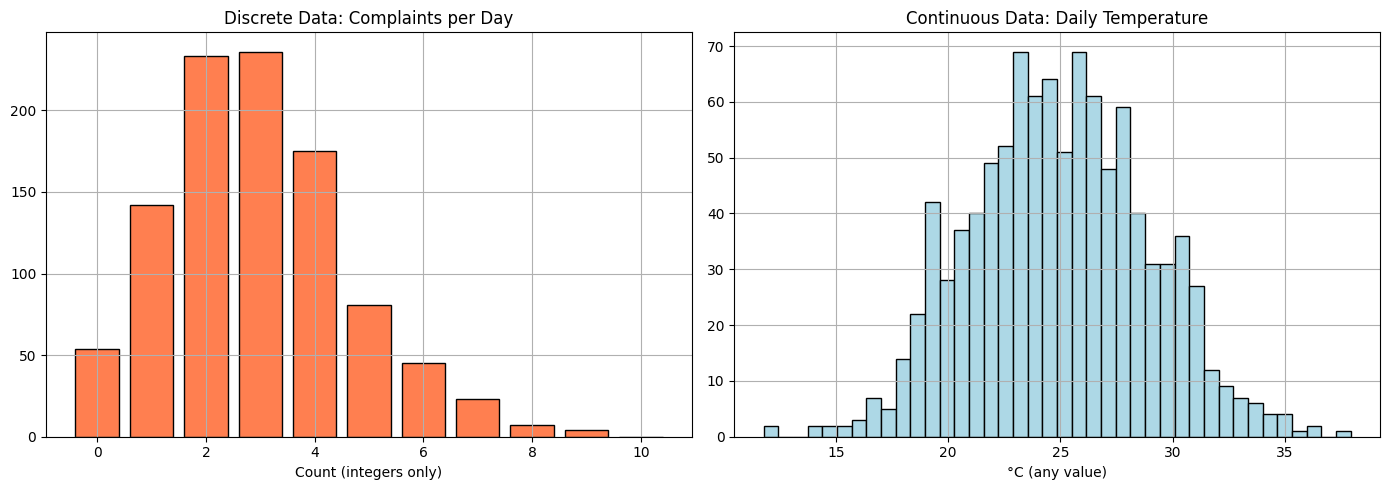

In [10]:
discrete_example = np.random.poisson(lam=3, size=1000)        # e.g., number of customer complaints/day
continuous_example = np.random.normal(loc=25, scale=4, size=1000)  # e.g., temperature

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(discrete_example, bins=np.arange(0, 12)-0.5, color='coral', edgecolor='black', rwidth=0.8)
axes[0].set_title("Discrete Data: Complaints per Day")
axes[0].set_xlabel("Count (integers only)")

axes[1].hist(continuous_example, bins=40, color='lightblue', edgecolor='black')
axes[1].set_title("Continuous Data: Daily Temperature")
axes[1].set_xlabel("°C (any value)")
plt.tight_layout()
plt.show()


## 14. What is Probability? What is Inferential Statistics? Why discuss Probability in ML?

**Probability** measures how likely an event is to happen, on a scale from **0 (impossible)** to **1 (certain)**.

$$ P(\text{Event}) = \frac{\text{Number of favorable outcomes}}{\text{Total number of possible outcomes}} $$

**Real-life example:** The probability of rolling a 4 on a fair 6-sided die = 1/6 ≈ 0.167.

**Inferential Statistics** uses a **sample** of data to draw conclusions/make predictions about a larger **population** (since we usually can't measure everyone/everything). *Example:* surveying 1,000 voters to estimate what all voters in a country think.

**Why probability matters in ML:**
- Classification models (e.g., logistic regression, neural nets) output **probabilities** (e.g., "85% chance this email is spam"), not hard yes/no answers.
- Model evaluation, confidence intervals, and A/B testing rely on **inferential statistics** to generalize from a training/test sample to real-world performance.
- Bayesian methods, Naive Bayes classifiers, and probabilistic graphical models are built entirely on probability theory.


## 15. Experiment, Trial, Random Experiment, Sample Space, Outcomes, Events, Favorable Outcomes

Let's define these using a **real-life example: rolling a single 6-sided die.**

| Term | Meaning | Example (rolling a die) |
|---|---|---|
| **Experiment** | A procedure that produces an observable result | Rolling the die |
| **Trial** | A single performance of the experiment | One roll |
| **Random Experiment** | An experiment whose outcome cannot be predicted with certainty | Rolling the die (you don't know the result in advance) |
| **Sample Space (S)** | The set of ALL possible outcomes | {1, 2, 3, 4, 5, 6} |
| **Outcome** | A single possible result | Getting a "4" |
| **Event** | A subset of the sample space (one or more outcomes) | "Rolling an even number" = {2, 4, 6} |
| **Favorable Outcomes** | Outcomes that satisfy the event of interest | {2, 4, 6} for the event "even number" |

Another example: **Experiment** = tossing a coin twice. **Sample space** = {HH, HT, TH, TT}. **Event** "at least one head" has **favorable outcomes** = {HH, HT, TH}.


## 16. Equally Likely Events

Events are **equally likely** when each has the **same probability of occurring** — no outcome is favored over another.

**Real-life example:** A fair coin toss — Heads and Tails are equally likely (50% each). A fair die roll — each face (1 through 6) is equally likely (1/6 each).

**Counter-example (NOT equally likely):** A biased spinner where the "red" section is bigger than the "blue" section — landing on red is more likely than landing on blue.


## 17. Exhaustive Events & Mutually Exclusive Events

- **Exhaustive events:** a set of events that together cover **every possible outcome** in the sample space — at least one of them MUST happen.
  - *Example:* For a die roll, {"1,2,3", "4,5,6"} is exhaustive — one of these two groups always occurs.
- **Mutually exclusive events:** events that **cannot happen at the same time** — if one occurs, the other cannot.
  - *Example:* Rolling a die and getting "an even number" and "an odd number" are mutually exclusive — a single roll can't be both.
  - *Counter-example (NOT mutually exclusive):* "rolling an even number" and "rolling a number > 3" — both can happen together (e.g., rolling a 4).

A set of events can be **both** exhaustive AND mutually exclusive — like {even, odd} for a die roll — together they cover everything, and they never overlap.


## 18. How we calculate probability — Basic Rules

1. **Classical/theoretical probability:**
   $$ P(A) = \frac{\text{favorable outcomes}}{\text{total outcomes}} $$
2. **P(A) is always between 0 and 1:** `0 ≤ P(A) ≤ 1`
3. **Sum of probabilities of all outcomes in the sample space = 1**
4. **Complement rule:** `P(not A) = 1 - P(A)`
   - *Example:* P(NOT rolling a 6) = 1 - 1/6 = 5/6

**Real-life example:** In a deck of 52 cards, P(drawing a heart) = 13/52 = 0.25. P(NOT drawing a heart) = 1 - 0.25 = 0.75.


## 19. Random Variable in ML

A **Random Variable** is a variable whose value is the numerical outcome of a random phenomenon. It maps outcomes of an experiment to numbers.

**Real-life example:** Let X = "number of heads in 3 coin tosses". X can take values {0, 1, 2, 3}, each with some probability — X is a random variable.

**In ML:** Every feature and every target in your dataset is treated as a **random variable** — this is the foundation of the entire probabilistic view of ML (e.g., "the model predicts the *expected value* of the target given the features").



## 21. Addition Rule & Conditional Probability

**Addition Rule** — probability that **A or B** happens:
$$ P(A \text{ or } B) = P(A) + P(B) - P(A \text{ and } B) $$
(If A and B are mutually exclusive, `P(A and B) = 0`, so it simplifies to `P(A) + P(B)`.)

*Real-life example:* P(drawing a King OR a Heart) = P(King) + P(Heart) − P(King of Hearts) = 4/52 + 13/52 − 1/52 = 16/52.

**Conditional Probability** — probability of A **given that** B has already happened:
$$ P(A \mid B) = \frac{P(A \text{ and } B)}{P(B)} $$

*Real-life example:* P(it rains today | it's cloudy this morning) is usually higher than P(it rains today) with no information — conditioning on evidence updates the probability. This is the backbone of **Naive Bayes classifiers** and **spam filters**: `P(spam | contains "free money")`.


## 22. Multiplication Rule

Rearranging the conditional probability formula gives the **Multiplication Rule** — probability that **A and B both** happen:
$$ P(A \text{ and } B) = P(A) \times P(B \mid A) $$

If A and B are **independent** (one doesn't affect the other), this simplifies to:
$$ P(A \text{ and } B) = P(A) \times P(B) $$

*Real-life example (independent):* P(coin shows Heads AND die shows 6) = P(Heads) × P(6) = 0.5 × (1/6) = 1/12.

*Real-life example (dependent):* P(drawing 2 Aces in a row, without replacement) = P(1st Ace) × P(2nd Ace | 1st was Ace) = (4/52) × (3/51).


## 24. What is a Probability Distribution?

A **Probability Distribution** describes **how probabilities are spread** over the possible values of a random variable — it tells you which values are likely and which are rare.

- For **discrete** variables → described by a **PMF** (Probability Mass Function)
- For **continuous** variables → described by a **PDF** (Probability Density Function)

**Real-life example:** the distribution of "number of goals scored per match" in football follows roughly a **Poisson distribution**; "adult height" follows a **Normal distribution**; "outcome of a single coin flip" follows a **Bernoulli distribution**.


## 26. PMF vs PDF

- **PMF (Probability Mass Function)** — for **discrete** random variables. `PMF(x) = P(X = x)` gives the *exact* probability of a specific value. Values of the PMF sum to 1.
  - *Example:* PMF of a die roll — P(X=1) = P(X=2) = ... = 1/6.
- **PDF (Probability Density Function)** — for **continuous** random variables. `PDF(x)` does NOT give a probability directly (since P(X = exact value) = 0 for continuous variables) — instead, the **area under the PDF curve** over a range gives the probability. The PDF integrates to 1 over all values.
  - *Example:* PDF of height — P(height between 170-175 cm) = area under the curve from 170 to 175.


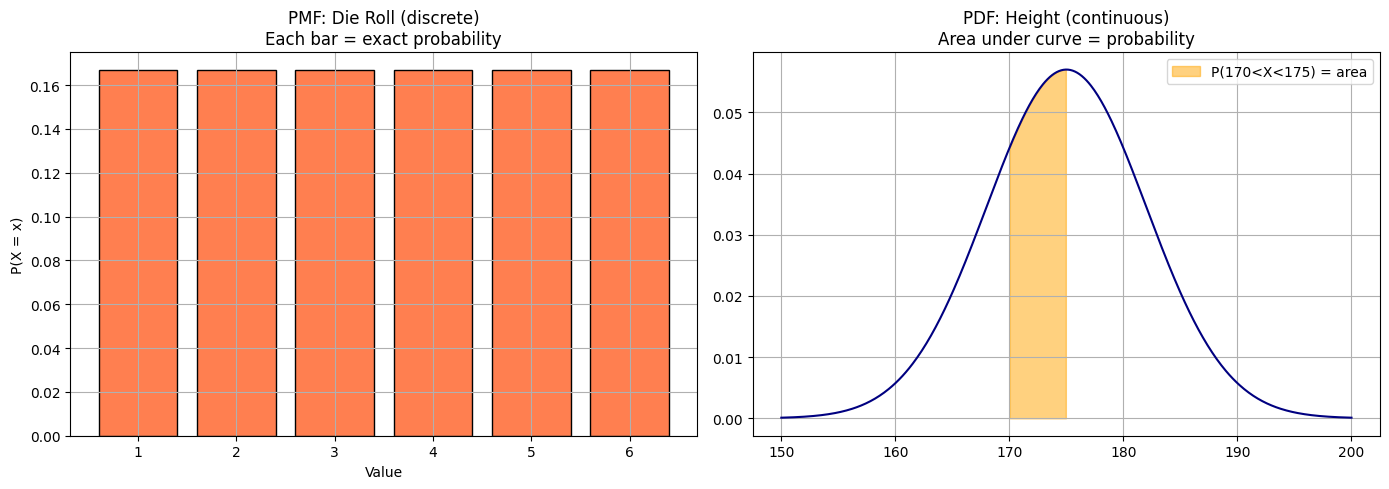

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# PMF: discrete (die roll)
values = [1,2,3,4,5,6]
probs = [1/6]*6
axes[0].bar(values, probs, color='coral', edgecolor='black')
axes[0].set_title("PMF: Die Roll (discrete)\nEach bar = exact probability")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("P(X = x)")

# PDF: continuous (height)
x = np.linspace(150, 200, 500)
y = stats.norm.pdf(x, 175, 7)
axes[1].plot(x, y, color='navy')
axes[1].fill_between(x, y, where=(x>=170)&(x<=175), color='orange', alpha=0.5, label='P(170<X<175) = area')
axes[1].set_title("PDF: Height (continuous)\nArea under curve = probability")
axes[1].legend()

plt.tight_layout()
plt.show()


## 27. Binomial Distribution

Models the number of **successes** in **n independent trials**, each with the same probability `p` of success.

$$ P(X=k) = \binom{n}{k} p^k (1-p)^{n-k} $$

**Real-life example:** Flipping a fair coin 10 times — what's the probability of getting exactly 6 heads? This is Binomial(n=10, p=0.5).

## 28. Bernoulli Distribution

The **simplest** distribution — models a **single trial** with only 2 outcomes: success (1) or failure (0), with probability `p` of success.

$$ P(X=1) = p, \quad P(X=0) = 1-p $$

**Real-life example:** A single coin flip (Heads=1, Tails=0), a single email being spam (1) or not (0), a single customer clicking (1) or not clicking (0) an ad.

**Relationship:** The **Binomial distribution is just the sum of `n` independent Bernoulli trials.** Bernoulli = Binomial with n=1.

**Use in ML:** Bernoulli underlies **binary classification** (logistic regression models `P(y=1|x)` as a Bernoulli probability). Binomial is used when counting successes across repeated binary trials, e.g., modeling "number of conversions out of N website visitors."
